# Articulation runtime summary

Read the append-only articulation JSONL log, retain the latest successful export per shape by default, and summarize whatever ordered stages each pipeline recorded. The parser does not assume stage names or a fixed stage count.

In [6]:
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display


def find_repository_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "articulate").is_dir():
            return candidate
    raise RuntimeError(f"Could not locate the ATM repository from {start}")


REPOSITORY_ROOT = find_repository_root(Path.cwd())
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from articulate.runtime_logging import (
    read_runtime_records,
    runtime_records_to_frames,
    select_runtime_records,
)

sns.set_theme(style="whitegrid")
REPOSITORY_ROOT

PosixPath('/home/knpob/work/code/atm-dev')

## Settings

Set `LOG_PATH` to any schema-compatible JSONL file. Set `RUN_ID` to a recorded UUID to inspect one command, or leave it as `None`. `LATEST_PER_SHAPE=True` uses append order to retain the newest successful export for each canonical input path.

In [7]:
LOG_PATH = Path(
    os.environ.get(
        "ARTICULATION_RUNTIME_LOG",
        REPOSITORY_ROOT / "output" / "articulation_runtime.jsonl",
    )
)
RUN_ID = None
LOG_PATH = Path(
    '../output/faust_raw/articulation_runtime.jsonl'
)
LATEST_PER_SHAPE = True

if not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"Runtime log not found: {LOG_PATH}\n"
        "Run the uncertainty_aware_parallel preset or update LOG_PATH."
    )

all_records = read_runtime_records(LOG_PATH)
records = select_runtime_records(
    all_records,
    latest_per_shape=LATEST_PER_SHAPE,
    run_id=RUN_ID,
)
if not records:
    raise RuntimeError("No runtime records matched the current settings")

record_frame, stage_frame, wide_frame = runtime_records_to_frames(records)
print(f"Loaded {len(all_records)} records; selected {len(records)} from {LOG_PATH}")

Loaded 20 records; selected 20 from ../output/faust_raw/articulation_runtime.jsonl


## Selected per-shape runtimes

Stage columns are discovered in first-observed log order. Missing stages remain `NaN`, which lets different pipeline variants share one log.

In [8]:
display(wide_frame.drop(columns="record_index").sort_values("lifecycle_seconds", ascending=False))

,run_id,pipeline,finished_at_utc,shape_name,shape_path,lifecycle_seconds,articulation_seconds,pose_shape_estimation,ransac_view_alignment,pose_alignment,surface_alignment
8,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:01:44.470454+00:00,tr_scan_092,/home/knpob/work/data/shape-original/faust_raw...,80.618293,77.230355,14.190481,13.075608,11.652050,38.312215
3,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T15:59:09.752331+00:00,tr_scan_090,/home/knpob/work/data/shape-original/faust_raw...,76.405252,73.052354,13.779710,11.510854,12.826167,34.935622
10,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:03:00.372989+00:00,tr_scan_093,/home/knpob/work/data/shape-original/faust_raw...,75.899207,72.623446,13.933127,14.557186,10.568067,33.565067
14,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:05:28.940356+00:00,tr_scan_095,/home/knpob/work/data/shape-original/faust_raw...,75.024532,71.911108,13.999996,12.052960,10.792259,35.065893
5,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:00:23.849017+00:00,tr_scan_091,/home/knpob/work/data/shape-original/faust_raw...,74.094597,70.715137,13.954802,11.226843,12.069216,33.464276
12,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:04:13.913686+00:00,tr_scan_094,/home/knpob/work/data/shape-original/faust_raw...,73.537346,70.474409,14.094038,12.389602,10.777403,33.213365
0,625d69e3-94f7-400c-b61b-fa00063a13ab,uncertainty_aware_parallel,2026-07-28T15:55:52.190107+00:00,tr_scan_080,/home/knpob/work/data/shape-original/faust_raw...,73.467385,70.213157,10.669893,11.474390,11.995827,36.073047
7,625d69e3-94f7-400c-b61b-fa00063a13ab,uncertainty_aware_parallel,2026-07-28T16:01:44.448101+00:00,tr_scan_085,/home/knpob/work/data/shape-original/faust_raw...,72.747965,69.657043,10.065019,15.313350,10.607403,33.671271
16,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:06:41.259641+00:00,tr_scan_096,/home/knpob/work/data/shape-original/faust_raw...,72.316354,69.004702,13.962277,11.582598,10.912568,32.547258
17,40246302-0a48-4532-8521-fd7455f0d81b,uncertainty_aware_parallel,2026-07-28T16:07:53.092351+00:00,tr_scan_097,/home/knpob/work/data/shape-original/faust_raw...,71.829555,68.584714,14.148191,12.185355,10.277854,31.973314


## Aggregate summaries

In [9]:
total_summary = (
    record_frame.groupby("pipeline", sort=False)[
        ["lifecycle_seconds", "articulation_seconds"]
    ]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

if stage_frame.empty:
    stage_summary = pd.DataFrame()
else:
    stage_order = stage_frame["stage"].drop_duplicates().tolist()
    stage_frame["stage"] = pd.Categorical(
        stage_frame["stage"], categories=stage_order, ordered=True
    )
    grouped_stages = stage_frame.groupby(
        ["pipeline", "stage"], sort=False, observed=True
    )["seconds"]
    stage_summary = grouped_stages.agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max",
    ).reset_index()
    stage_p95 = grouped_stages.quantile(0.95).rename("p95").reset_index()
    stage_summary = stage_summary.merge(
        stage_p95, on=["pipeline", "stage"], how="left"
    )

display(total_summary)
display(stage_summary)

lifecycle_seconds                                  \
                                       count       mean     median       std   
pipeline                                                                       
uncertainty_aware_parallel                20  72.538572  71.767829  2.859488   

                                                 articulation_seconds  \
                                  min        max                count   
pipeline                                                                
uncertainty_aware_parallel  68.182233  80.618293                   20   

                                                                       \
                                 mean     median       std        min   
pipeline                                                                
uncertainty_aware_parallel  69.140406  68.476636  3.001731  64.601819   

                                       
                                  max  
pipeline                               
uncertainty_aware_parallel  77.230355

,pipeline,stage,count,mean,median,std,minimum,maximum,p95
0,uncertainty_aware_parallel,pose_shape_estimation,20,11.943604,11.683810,1.924484,9.976691,14.190481,14.150305
1,uncertainty_aware_parallel,ransac_view_alignment,20,12.140301,11.552487,1.247509,10.812203,15.313350,14.594994
2,uncertainty_aware_parallel,pose_alignment,20,11.362810,10.870437,1.067885,10.262606,14.116416,13.033883
3,uncertainty_aware_parallel,surface_alignment,20,33.693691,33.368887,1.701511,31.418298,38.312215,36.385903


## Dynamic stage plots

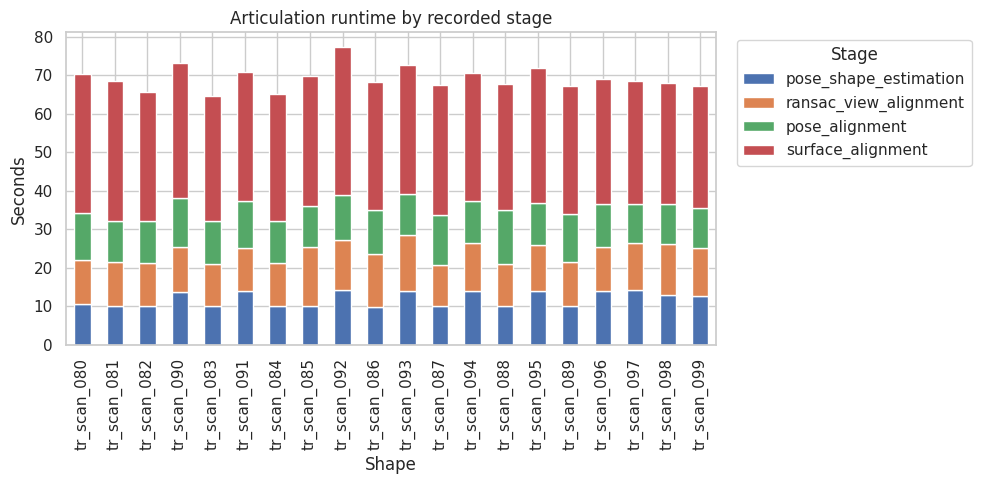

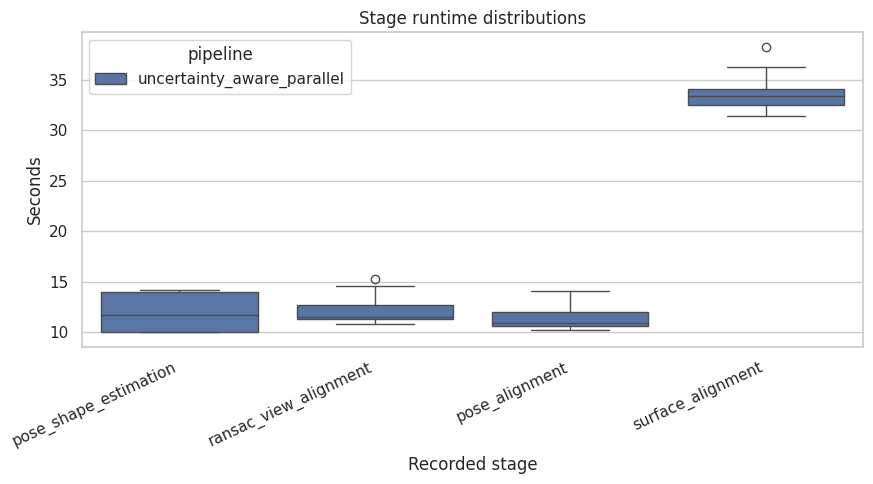

In [10]:
stage_columns = stage_frame["stage"].astype(str).drop_duplicates().tolist()
if stage_columns:
    per_shape_plot = wide_frame.set_index("shape_name")[stage_columns]
    axis = per_shape_plot.plot(
        kind="bar",
        stacked=True,
        figsize=(max(10, len(per_shape_plot) * 0.45), 5),
    )
    axis.set_ylabel("Seconds")
    axis.set_xlabel("Shape")
    axis.set_title("Articulation runtime by recorded stage")
    axis.legend(title="Stage", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(max(9, len(stage_columns) * 1.5), 5))
    sns.boxplot(data=stage_frame, x="stage", y="seconds", hue="pipeline")
    plt.xlabel("Recorded stage")
    plt.ylabel("Seconds")
    plt.title("Stage runtime distributions")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

### Interpretation checklist

- `lifecycle_seconds` includes loading, view rendering, articulation, and export for the successful attempt.
- `articulation_seconds` is the sum of the stages present in that record.
- Repeated shapes are not averaged by default: the last appended successful record wins.
- Compare runs only when device, view count, batch settings, and optimization iteration counts are compatible.